## 

Implementing various convolutional kernels as reconstruction filters. 



### 

Can use the prebuilt packages from scikit-image. 

Things to replace with our own functions would be: 

- Forward radon transform
- Filters
- inverse radon transform 

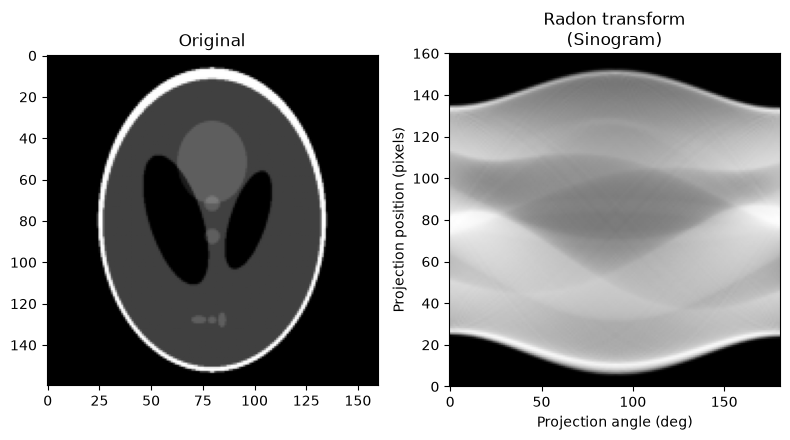

In [7]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.data import shepp_logan_phantom, horse, brain
from skimage.transform import radon, rescale

image1 = shepp_logan_phantom()
image1 = rescale(image1, scale=0.4, mode='reflect', channel_axis=None)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4.5))

ax1.set_title("Original")
ax1.imshow(image1, cmap=plt.cm.Greys_r)

theta = np.linspace(0.0, 180.0, max(image1.shape), endpoint=False)
sinogram1 = radon(image1, theta=theta)
dx, dy = 0.5 * 180.0 / max(image1.shape), 0.5 / sinogram1.shape[0]
ax2.set_title("Radon transform\n(Sinogram)")
ax2.set_xlabel("Projection angle (deg)")
ax2.set_ylabel("Projection position (pixels)")
ax2.imshow(
    sinogram1,
    cmap=plt.cm.Greys_r,
    extent=(-dx, 180.0 + dx, -dy, sinogram1.shape[0] + dy),
    aspect='auto',
)

fig.tight_layout()
plt.show()





FBP rms reconstruction error: 0.0283


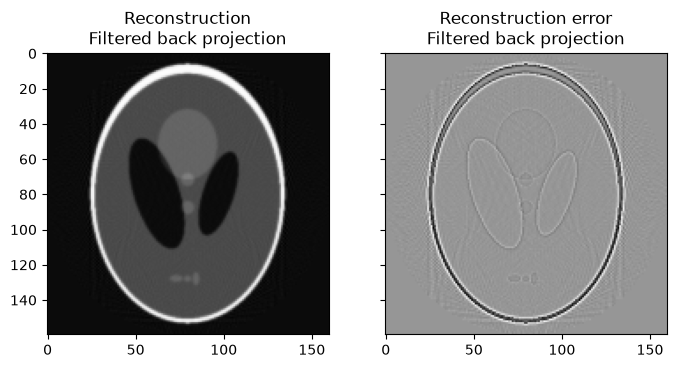

In [8]:
from skimage.transform import iradon

reconstruction_fbp = iradon(sinogram1, theta=theta, filter_name='ramp')
error = reconstruction_fbp - image1
print(f'FBP rms reconstruction error: {np.sqrt(np.mean(error**2)):.3g}')

imkwargs = dict(vmin=-0.2, vmax=0.2)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4.5), sharex=True, sharey=True)
ax1.set_title("Reconstruction\nFiltered back projection")
ax1.imshow(reconstruction_fbp, cmap=plt.cm.Greys_r)
ax2.set_title("Reconstruction error\nFiltered back projection")
ax2.imshow(reconstruction_fbp - image1, cmap=plt.cm.Greys_r, **imkwargs)
plt.show()

c:\Users\mthompson46\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\_skimage2\transform\radon_transform.py:74: UserWarning: Radon transform: image must be zero outside the reconstruction circle
  warn(


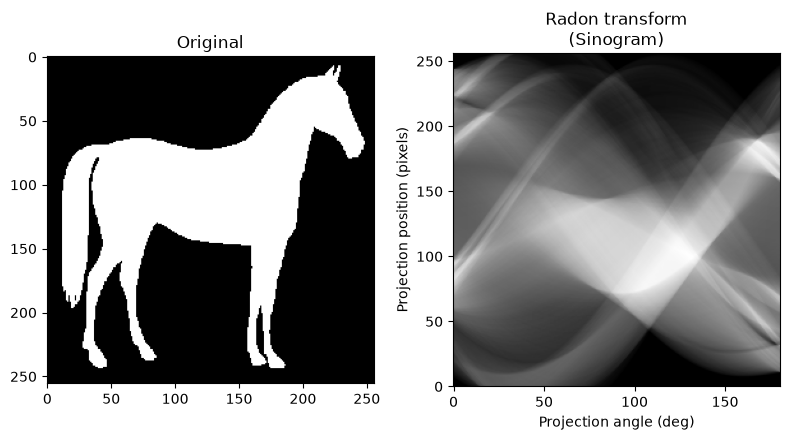

In [15]:
from skimage.util import invert
from skimage.transform import resize

image2 = horse()
image2 = resize(image2, output_shape=(256, 256), mode='reflect')
image2 = invert(image2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4.5))

ax1.set_title("Original")
ax1.imshow(image2, cmap=plt.cm.Greys_r)

theta = np.linspace(0.0, 180.0, max(image2.shape), endpoint=False)
sinogram2 = radon(image2, theta=theta)
dx, dy = 0.5 * 180.0 / max(image2.shape), 0.5 / sinogram2.shape[0]
ax2.set_title("Radon transform\n(Sinogram)")
ax2.set_xlabel("Projection angle (deg)")
ax2.set_ylabel("Projection position (pixels)")
ax2.imshow(
    sinogram2,
    cmap=plt.cm.Greys_r,
    extent=(-dx, 180.0 + dx, -dy, sinogram2.shape[0] + dy),
    aspect='auto',
)

fig.tight_layout()
plt.show()

FBP rms reconstruction error: 0.167


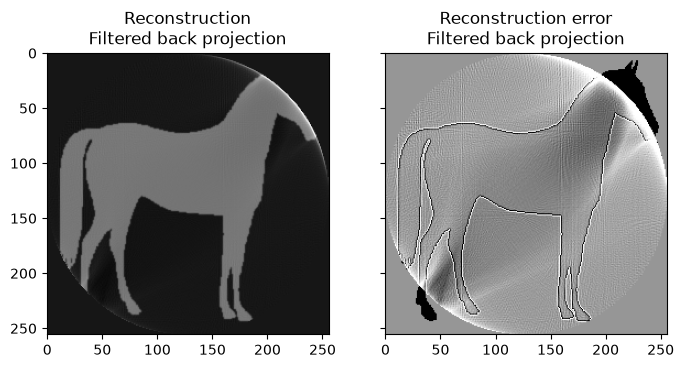

In [16]:
from skimage.transform import iradon

reconstruction_fbp = iradon(sinogram2, theta=theta, filter_name='ramp')
error = reconstruction_fbp - image2
print(f'FBP rms reconstruction error: {np.sqrt(np.mean(error**2)):.3g}')

imkwargs = dict(vmin=-0.2, vmax=0.2)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4.5), sharex=True, sharey=True)
ax1.set_title("Reconstruction\nFiltered back projection")
ax1.imshow(reconstruction_fbp, cmap=plt.cm.Greys_r)
ax2.set_title("Reconstruction error\nFiltered back projection")
ax2.imshow(reconstruction_fbp - image2, cmap=plt.cm.Greys_r, **imkwargs)
plt.show()

c:\Users\mthompson46\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\_skimage2\transform\radon_transform.py:74: UserWarning: Radon transform: image must be zero outside the reconstruction circle
  warn(


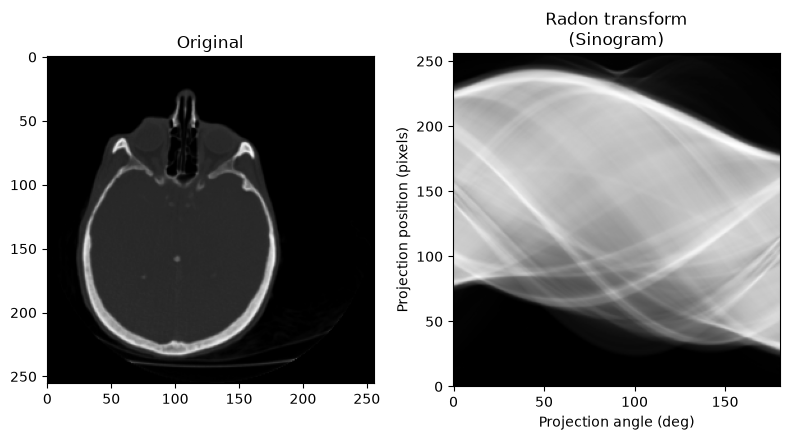

In [20]:
image3 = brain()[8]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4.5))

ax1.set_title("Original")
ax1.imshow(image3, cmap=plt.cm.Greys_r)

theta = np.linspace(0.0, 180.0, max(image3.shape), endpoint=False)
sinogram3 = radon(image3, theta=theta)
dx, dy = 0.5 * 180.0 / max(image3.shape), 0.5 / sinogram3.shape[0]
ax2.set_title("Radon transform\n(Sinogram)")
ax2.set_xlabel("Projection angle (deg)")
ax2.set_ylabel("Projection position (pixels)")
ax2.imshow(
    sinogram3,
    cmap=plt.cm.Greys_r,
    extent=(-dx, 180.0 + dx, -dy, sinogram3.shape[0] + dy),
    aspect='auto',
)

fig.tight_layout()
plt.show()


FBP rms reconstruction error: 7.19e+03


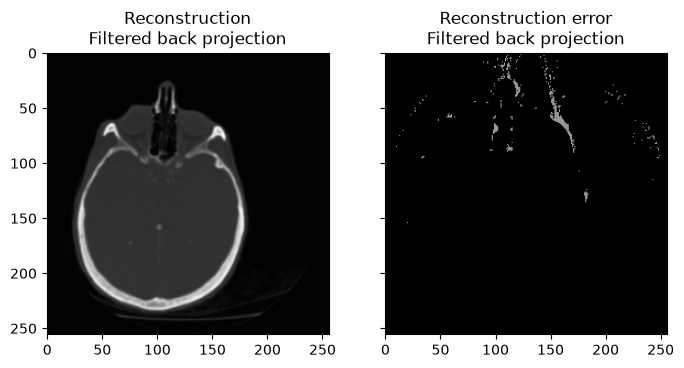

In [21]:
from skimage.transform import iradon

reconstruction_fbp = iradon(sinogram3, theta=theta, filter_name='ramp')
error = reconstruction_fbp - image3
print(f'FBP rms reconstruction error: {np.sqrt(np.mean(error**2)):.3g}')

imkwargs = dict(vmin=-0.2, vmax=0.2)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4.5), sharex=True, sharey=True)
ax1.set_title("Reconstruction\nFiltered back projection")
ax1.imshow(reconstruction_fbp, cmap=plt.cm.Greys_r)
ax2.set_title("Reconstruction error\nFiltered back projection")
ax2.imshow(reconstruction_fbp - image3, cmap=plt.cm.Greys_r, **imkwargs)
plt.show()

## To add: 


replace Radon and iRadon functions with own implementation

other filters, 
- Cylindrical approximate dirac measure (constant function)
- Linear hat (schuester)
- Gaussian

add noise to projection data